# សប្ដាហ៍ទី 2 · វិធាន និងការសម្រេចចិត្ត

ប្រព័ន្ធព័ត៌មានធ្វើតាមវិធាន ដែលមនុស្សជាអ្នកសម្រេច។ សប្ដាហ៍នេះ អ្នកនឹងសរសេរវិធានពីរក្នុងចំណោមនោះជា Python, test វានៅត្រង់ព្រំដែន ហើយជ្រើសរើសលេខដោយខ្លួនឯង។

| | |
|---|---|
| **សំណួរសប្ដាហ៍នេះ** | តើប្រព័ន្ធធ្វើការសម្រេចចិត្តដោយរបៀបណា ហើយនរណាជាអ្នកជ្រើសរើសវិធាន? |
| **Python ដែលអ្នកនឹងរៀន** | ការប្រៀបធៀប, `True`/`False`, `and`/`or`/`not`, `if`/`elif`/`else`, function តូចមួយដំបូង |
| **គោលការណ៍ទី 2** | **វិធានច្បាស់លាស់។** ដាក់ឈ្មោះឱ្យលេខរបស់អ្នក គ្របដណ្ដប់គ្រប់ករណី ហើយ test ព្រំដែន (boundary)។ |
| **ផ្នែកដែលអ្នកបង្កើត** | `pickup_label` (hold, team ឬ standard) និង `urgency` (urgent, soon ឬ later) |

*Campus Food Rescue ជាករណីប្រឌិត។ អង្គការ មនុស្ស និងលេខទាំងអស់ សុទ្ធតែប្រឌិតឡើង។*

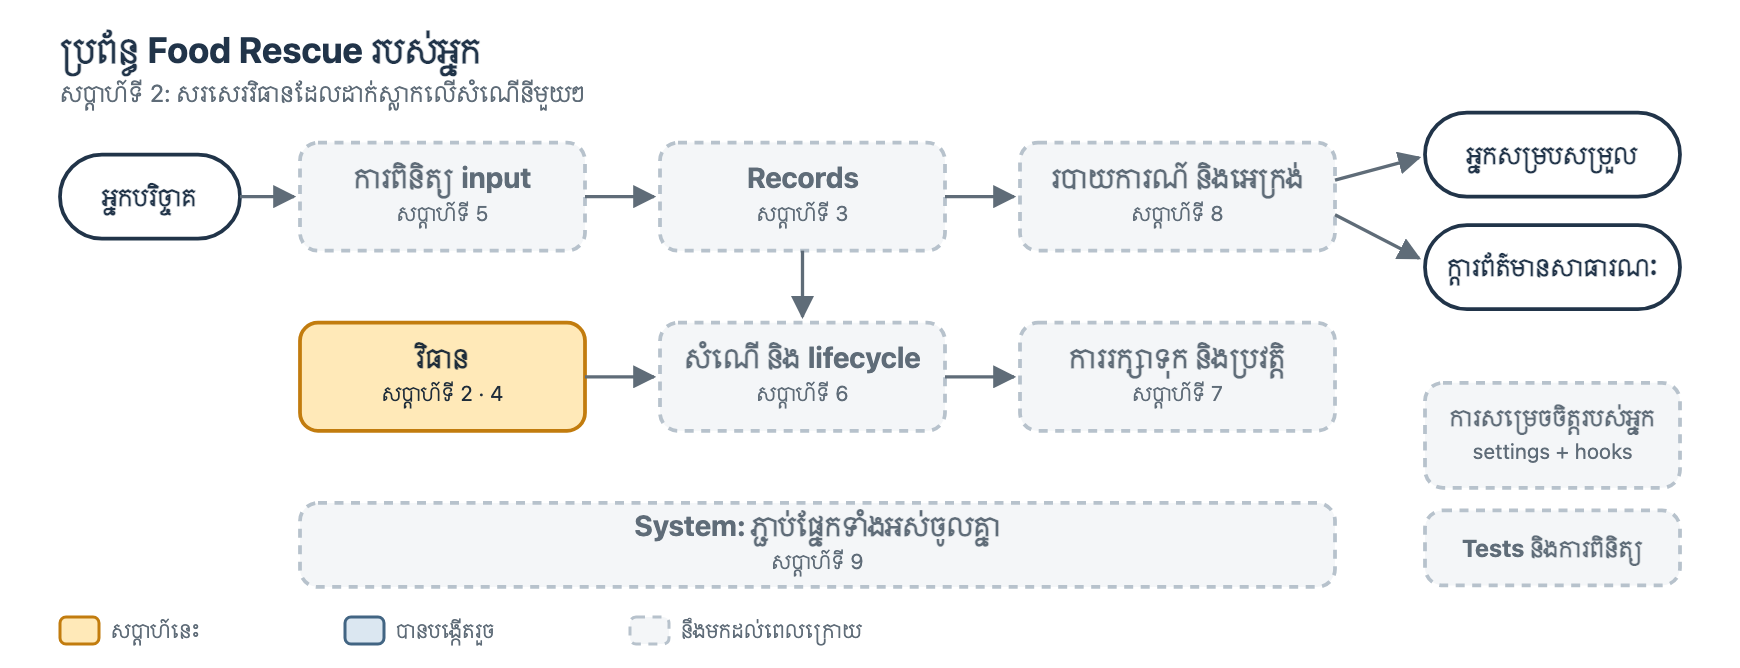

## មុនពេលចាប់ផ្ដើម

1. **File → Save a copy in Drive** រួចធ្វើការក្នុងច្បាប់ចម្លងរបស់អ្នក។
2. Run setup cell។ Run វាម្ដងទៀត ក្រោយពេល runtime restart។
3. ⭐ = មូលដ្ឋាន សម្រាប់គ្រប់គ្នា, ⭐⭐ = បន្ថែម (ស្រេចចិត្ត)។

In [ ]:
# @title ▶ សូម run cell នេះមុនគេ (setup) — វារៀបចំប្រព័ន្ធ Food Rescue
# វាដកយក (unpack) ប្រព័ន្ធរបស់វគ្គសិក្សា ដែលរក្សាទុកនៅក្នុង notebook នេះ។
# មិនត្រូវការ internet ឬ install អ្វីទេ។ សូម run វាម្ដងទៀត ក្រោយពេល Colab restart។
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.2"
_KIT_SHA = "87d59ca87437a3c6cc62441c2e95bfb0b252ea6b51ab2ccb7b2875f022775c3a"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("ឯកសាររបស់វគ្គសិក្សាក្នុង notebook នេះខូច។ សូមទាញយកច្បាប់ថ្មីមួយ។")
    marker = os.path.join("food_rescue_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("food_rescue_kit/my_settings.py", "food_rescue_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("food_rescue_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "rescue" or m.startswith("rescue.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import rescue as fr
fr.set_language("km")         # screens and checks in Khmer
print("✅ ប្រព័ន្ធ Food Rescue រួចរាល់ហើយ (version " + fr.KIT_VERSION + ")។ អ្នកអាចបន្តបាន។")


## ចាប់ផ្ដើមថ្នាក់ · ចែករំលែកកិច្ចការស្រាវជ្រាវទី 1 (10 នាទី)

ជាក្រុមបីនាក់ ចែករំលែកប្រព័ន្ធព័ត៌មានដែលអ្នកបានស្រាវជ្រាវ។

1. នរណាប្រើវា ហើយវារក្សាទុកទិន្នន័យអ្វីខ្លះ?
2. តើអ្នកបានរកឃើញ **វិធាន** អ្វី? តើវិធាននោះត្រូវបានសរសេរទុកនៅកន្លែងណាមួយ ឬមានតែនៅក្នុងក្បាលមនុស្ស?
3. តើអាចមានអ្វីខុស ហើយនរណានឹងរងគ្រោះ?

📝 **គំនិតមួយពីមិត្តរួមថ្នាក់ ដែលខ្ញុំចង់ចងចាំ:**

## វគ្គទី 1 · រៀន: របៀបដែល program សម្រេចចិត្ត (30 នាទី)

### គំនិតសំខាន់: វិធានអាជីវកម្ម (business rule)

**វិធានអាជីវកម្ម (business rule)** គឺជាការសម្រេចចិត្តរបស់អង្គការមួយ អំពីរបៀបធ្វើការងារ។ ឧទាហរណ៍: *"ពិន្ទុប្រឡងពី 50 ឡើងទៅ គឺជាប់។"* *"កុមារអាយុក្រោម 6 ឆ្នាំ ធ្វើដំណើរដោយឥតគិតថ្លៃ។"* នៅក្នុងប្រព័ន្ធរបស់យើង អ្នកសម្របសម្រួលនិយាយថា:

> *"បើសំណើមួយមិនទាន់ត្រូវបានអនុម័តទេ វារង់ចាំ (**hold**)។ បើវាត្រូវបានអនុម័ត ហើយមាន **20 ចំណែក ឬច្រើនជាងនេះ** យើងបញ្ជូនជា **ក្រុម (team)**។ បើមិនដូច្នោះទេ អ្នកស្ម័គ្រចិត្តម្នាក់គឺគ្រប់គ្រាន់ (**standard**)។"*

មនុស្សជាអ្នកជ្រើសរើសវិធាន។ Program អនុវត្តវាតាមរបៀបដដែលរាល់ដង ចំពោះសំណើគ្រប់មួយ នៅគ្រប់ម៉ោង។ នេះមានប្រយោជន៍ ហើយក៏គ្រោះថ្នាក់ដែរ: វិធានខុស ត្រូវបានអនុវត្តខុសរាល់ដង។ ដូច្នេះ វិធានត្រូវតែ **សរសេរឱ្យបានច្បាស់លាស់** និង **test នៅត្រង់ព្រំដែន**។

### 1 · ការប្រៀបធៀបផ្ដល់ `True` ឬ `False`

| Python | អត្ថន័យ |
|---|---|
| `==` `!=` | ស្មើ, មិនស្មើ |
| `<` `<=` | តូចជាង, តូចជាង ឬស្មើ |
| `>` `>=` | ធំជាង, ធំជាង ឬស្មើ |

🤔 **ទាយមើល** បន្ទាត់នីមួយៗ មុននឹង run cell។

In [ ]:
portions = 20
print(portions >= 20)
print(portions > 20)
print(portions == 20)
print("bread" == "Bread")

**ការទាយ:** …  **លទ្ធផល:** …  **រឿងដែលធ្វើឱ្យភ្ញាក់ផ្អើល:** …

បន្ទាត់ចុងក្រោយគឺ `False`: ការប្រៀបធៀប text ត្រូវតែដូចគ្នាបេះបិទ ដូច្នេះអក្សរធំ និងអក្សរតូចគឺខុសគ្នា។ "20 ឬច្រើនជាងនេះ" គឺ `>= 20`; "ច្រើនជាង 20" គឺ `> 20`។ តួអក្សរតែមួយ អាចប្ដូរថានរណាបានក្រុម។

### 2 · ការផ្សំលក្ខខណ្ឌ: `and`, `or`, `not`

In [ ]:
approved = True
portions = 25
print(approved and portions >= 20)   # ទាំងពីរត្រូវតែ True
print(not approved)                  # ផ្ទុយ
print(portions >= 20 or portions < 0)  # យ៉ាងហោចណាស់មួយត្រូវតែ True

### 3 · `if` និង `else`: ជ្រើសរើសអ្វីដែលត្រូវ run

In [ ]:
temperature = 31
if temperature >= 30:
    print("Hot: keep the food in the shade")
else:
    print("Normal temperature")
print("This line always runs")

- បន្ទាត់ដែលមាន `if` បញ្ចប់ដោយសញ្ញា colon `:`។
- បន្ទាត់ដែលជារបស់វា ត្រូវ **ចូលបន្ទាត់ (indent)** 4 ដកឃ្លា (spaces)។ នៅក្នុង Python ការចូលបន្ទាត់មិនមែនសម្រាប់លម្អទេ; វាកំណត់ថាបន្ទាត់ណាជារបស់អ្វី។

### 4 · `elif`: ជម្រើសច្រើនជាងពីរ ពិនិត្យតាមលំដាប់

Python ពិនិត្យលក្ខខណ្ឌ **ពីលើចុះក្រោម** ហើយ run តែ branch **ទីមួយ** ដែលជា `True` ប៉ុណ្ណោះ។

In [ ]:
mark = 72
if mark >= 80:
    grade = "A"
elif mark >= 65:
    grade = "B"
elif mark >= 50:
    grade = "C"
else:
    grade = "fail"
print(grade)

🤔 ពិន្ទុ 65 គត់ ទទួលបាននិទ្ទេសអ្វី? ចុះ 64 វិញ? ប្ដូរ `mark` ហើយពិនិត្យមើល។

**ចម្លើយរបស់ខ្ញុំ:** …

### 5 · ដាក់ឈ្មោះឱ្យលេខរបស់អ្នក

លេខនៅក្នុងវិធាន គឺជា **ការសម្រេចចិត្ត**។ ដាក់ឈ្មោះឱ្យវា ដើម្បីឱ្យមនុស្សអាចរកឃើញ យល់ និងប្ដូរវានៅកន្លែងតែមួយ។ តាមទម្លាប់ ឈ្មោះដែលសរសេរជាអក្សរធំទាំងអស់ គឺជា constant: value ដែល program មិនគួរប្ដូរ ពេលវាកំពុង run។

```python
TEAM_PICKUP_MIN_PORTIONS = 20      # អ្នកសម្របសម្រួលជាអ្នកសម្រេច

if portions >= TEAM_PICKUP_MIN_PORTIONS:
    ...
```

### 6 · Function ដំបូង: វេចខ្ចប់វិធានមួយ

**Function** មួយដាក់ឈ្មោះឱ្យវិធាន ទទួល input ហើយ **return** ចម្លើយមួយ។ អ្នកនឹងរៀន function ឱ្យបានពេញលេញនៅសប្ដាហ៍ទី 4។ សម្រាប់ពេលនេះ គំរូគឺ:

In [ ]:
def is_hot(temperature):
    if temperature >= 30:
        return True
    return False

print(is_hot(31))
print(is_hot(25))

- `def` ចាប់ផ្ដើម function; `temperature` គឺជា input របស់វា។
- `return` បញ្ជូនចម្លើយត្រឡប់មកវិញ ហើយ **បញ្ឈប់** function។
- អ្នកអាចហៅ (call) វិធានដដែលនេះច្រើនដង ជាមួយ input ផ្សេងៗគ្នា។ នោះហើយជាអ្វីដែលប្រព័ន្ធធ្វើ សម្រាប់សំណើនីមួយៗ។

## វគ្គទី 2 · អនុវត្ត និងវាយតម្លៃ (60 នាទី)

### ⭐ P1 · ទាយលទ្ធផលនៃការប្រៀបធៀប

សរសេរការទាយរបស់អ្នកសម្រាប់បន្ទាត់នីមួយៗ រួច run។

In [ ]:
hours_left = 3
print(hours_left <= 3)
print(hours_left < 3)
print(hours_left != 3)
print(hours_left >= 1 and hours_left <= 12)
print(not hours_left > 12)

**ការទាយ:** …  **លទ្ធផល:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

`True`, `False`, `False`, `True`, `True`។ បន្ទាត់ទីពីរគឺជាអន្ទាក់ព្រំដែន: `3 < 3` គឺ `False`។

</details>

### ⭐ P2 · ជួសជុល bug នៅព្រំដែន

វិធានរបស់អ្នកសម្របសម្រួលគឺ *"20 ចំណែក **ឬច្រើនជាងនេះ** ត្រូវការក្រុម។"* Code នេះមាន bug មួយ។ Test វាជាមួយ 19, 20 និង 21 រក bug ហើយជួសជុលវា។

In [ ]:
def needs_team(portions):
    if portions > 20:
        return True
    return False

print(19, needs_team(19))
print(20, needs_team(20))   # តើនេះគួរតែជាអ្វី?
print(21, needs_team(21))

<details><summary>មើលចម្លើយគំរូមួយ</summary>

`> 20` ត្រូវតែជា `>= 20`។ មានតែករណី **ព្រំដែន** (20 គត់) ទេ ដែលបង្ហាញ bug នេះ; 19 និង 21 មើលទៅត្រឹមត្រូវ។ នេះហើយជាមូលហេតុដែលយើងតែងតែ test នៅព្រំដែន មិនមែនត្រឹមតែ value ធម្មតាមួយទេ។

</details>

### ⭐ P3 · ជួសជុលលំដាប់របស់ branch

វិធានភាពបន្ទាន់: **3 ម៉ោង ឬតិចជាងនេះ** គឺ urgent (បន្ទាន់), **12 ម៉ោង ឬតិចជាងនេះ** គឺ soon (ឆាប់ៗ), លើសពីនេះគឺ later (ពេលក្រោយ)។ Version នេះមិនដែលនិយាយថា "urgent" ទេ។ ហេតុអ្វី? ជួសជុលវាដោយប្ដូរលំដាប់របស់ branch។

In [ ]:
def urgency_level(hours_left):
    if hours_left <= 12:
        return "soon"
    elif hours_left <= 3:
        return "urgent"
    else:
        return "later"

print(urgency_level(2), urgency_level(3), urgency_level(4), urgency_level(13))

**ហេតុអ្វីវាមិនដែលនិយាយថា urgent:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

2 ម៉ោងក៏ `<= 12` ដែរ ដូច្នេះ branch ទីមួយឈ្នះ ហើយ function return `"soon"` មុនពេលវាបានពិនិត្យ `<= 3`។ ដាក់លក្ខខណ្ឌដែល **ចង្អៀតបំផុត** មុនគេ។ លទ្ធផលដែលរំពឹងទុកក្រោយពេលជួសជុល: `urgent urgent soon later`។

</details>

### ⭐ P4 · សរសេរវិធានតូចមួយ

ផ្ទះបាយរបស់អង្គការដៃគូមួយ អាចទទួលអាហារដែលដឹកមកបាន **យ៉ាងច្រើនបំផុត 50 ចំណែក**។ សរសេរ `fits_kitchen(portions)` ដែល return `True` ឬ `False`។ ប្រើ constant ដែលមានឈ្មោះ។ Test 49, 50 និង 51។

In [ ]:
KITCHEN_MAX_PORTIONS = 50

def fits_kitchen(portions):
    # TODO: return True ពេល portions មិនលើស KITCHEN_MAX_PORTIONS
    return None

print(fits_kitchen(49), fits_kitchen(50), fits_kitchen(51))

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
def fits_kitchen(portions):
    return portions <= KITCHEN_MAX_PORTIONS
```

ការប្រៀបធៀបមួយ **គឺជា** `True` ឬ `False` រួចទៅហើយ ដូច្នេះអ្នកអាច return វាដោយផ្ទាល់។ លទ្ធផលដែលរំពឹងទុក: `True True False`។

</details>

### ⭐⭐ S1 · លក្ខខណ្ឌពីរ

អ្នកស្ម័គ្រចិត្តចង់បានវិធានពិសេសមួយ: បញ្ជូនក្រុមមួយ ពេលសំណើ **ធំ (20+) ឬបន្ទាន់ខ្លាំង (2 ម៉ោង ឬតិចជាងនេះ)** ប៉ុន្តែលុះត្រាតែវាត្រូវបានអនុម័ត។ សរសេរ `send_team(portions, hours_left, approved)` ហើយ test ករណីបួនដែលអ្នកជ្រើសរើស រួមទាំងករណីព្រំដែនមួយ។

In [ ]:
def send_team(portions, hours_left, approved):
    return None   # សរសេរវិធានរបស់អ្នកនៅទីនេះ

### ⚖️ ល្អ ឬមានហានិភ័យ?

ជំនួយការ AI មួយបានសរសេរ **Version A** សម្រាប់វិធានរបស់អ្នកសម្របសម្រួល។ **Version B** គឺជាការសរសេរឡើងវិញ។ ទាំងពីរ run ដោយគ្មាន error។

**Version A**

```python
def label(p, a):
    if p > 20 and a == True:
        return "team"
    elif a == True:
        return "standard"
```

**Version B**

```python
TEAM_PICKUP_MIN_PORTIONS = 20

def pickup_label(portions, approved):
    if not approved:
        return "hold"
    if portions >= TEAM_PICKUP_MIN_PORTIONS:
        return "team"
    return "standard"
```

ប្រើ **គោលការណ៍ទី 2 (វិធានច្បាស់លាស់)**។ រកបញ្ហា **យ៉ាងហោចណាស់បី** ក្នុង Version A។ សម្រាប់បញ្ហានីមួយៗ ប្រាប់ថាសំណើណាដែលនឹងត្រូវបានដោះស្រាយខុស។

📝 **បញ្ហាដែលខ្ញុំបានរកឃើញក្នុង Version A:**

1.
2.
3.

<details><summary>មតិរបស់គ្រូ</summary>

1. **ព្រំដែន:** `p > 20` ឱ្យសំណើ 20 ចំណែកគត់ ទៅយកតាមរបៀប standard ដែលផ្ទុយនឹងវិធាន។
2. **ករណីដែលខ្វះ:** ពេល `a` ជា `False` គ្មានអ្វីត្រូវបាន return ទេ ដូច្នេះ function ផ្ដល់ `None` មិនមែន `"hold"` ទេ។ អេក្រង់នឹងបង្ហាញ "None" ឬ program អាច crash នៅពេលក្រោយ។
3. **ការសម្រេចចិត្តដែលលាក់:** លេខ 20 ត្រូវបានកប់នៅក្នុង code។ គ្មាននរណាអាចមើលឃើញ ឬប្ដូរការសម្រេចចិត្តរបស់អ្នកសម្របសម្រួលបានទេ បើមិនអាន logic របស់វា។
4. **ឈ្មោះ:** `p` និង `a` មិនប្រាប់អ្វីសោះ។ (`a == True` ក៏ដំណើរការដែរ ប៉ុន្តែវែងជាង `a`។)

Version B ដោះស្រាយគ្រប់ករណី ដាក់ "មិនទាន់អនុម័ត" មុនគេ ដើម្បីកុំឱ្យវាត្រូវបានរំលងឡើយ ហើយដាក់ឈ្មោះឱ្យការសម្រេចចិត្ត។ Code ដែល AI សរសេរ ជារឿយៗ *មើលទៅ* ដូចជារួចរាល់; ការវាយតម្លៃវា មានន័យថា test នៅព្រំដែន ហើយសួរថា "តើមានអ្វីកើតឡើងក្នុងគ្រប់ករណី?"

</details>

## វគ្គទី 3 · បង្កើតផ្នែករបស់អ្នក: វិធានទៅយកអាហារ (60–80 នាទី)

សំណើនីមួយៗនៅលើអេក្រង់អ្នកសម្របសម្រួល មានស្លាកពីរ: ស្លាក **របៀបទៅយក** (pickup: នរណាទៅ) និងស្លាក **ភាពបន្ទាន់** (urgency: ត្រូវទៅឆាប់ប៉ុណ្ណា)។ ថ្ងៃនេះ អ្នកសរសេរវិធានទាំងពីរ។ បន្ទាប់មក អ្នកដោតវាចូលក្នុងប្រព័ន្ធពិត: function របស់អ្នកនឹងដាក់ស្លាកលើសំណើគ្រប់មួយ។

### ផ្នែកទី 1 · `pickup_label`

វិធាន: មិនទាន់អនុម័ត → `"hold"` (រង់ចាំការអនុម័ត)។ បានអនុម័ត ហើយមានយ៉ាងហោចណាស់ `TEAM_PICKUP_MIN_PORTIONS` → `"team"` (ទៅជាក្រុម)។ បើមិនដូច្នោះទេ → `"standard"` (ធម្មតា)។ Return ពាក្យទាំងនេះឱ្យដូចបេះបិទ ជាអក្សរតូច។

In [ ]:
TEAM_PICKUP_MIN_PORTIONS = 20

def pickup_label(portions, approved):
    # TODO 1: បើសំណើមិនទាន់ត្រូវបានអនុម័ត return "hold"
    # TODO 2: បើ portions មានយ៉ាងហោចណាស់ TEAM_PICKUP_MIN_PORTIONS return "team"
    # TODO 3: បើមិនដូច្នោះទេ return "standard"
    return "?"

ឥឡូវ ពិនិត្យវា។ ការពិនិត្យនេះ test ករណីព្រំដែន **នៃលេខរបស់អ្នកផ្ទាល់** ដូច្នេះវានៅតែដំណើរការ ពេលអ្នកប្ដូរវិធាននៅពេលក្រោយ។

In [ ]:
fr.check("pickup_label", pickup_label, {"TEAM_PICKUP_MIN_PORTIONS": TEAM_PICKUP_MIN_PORTIONS})

### ផ្នែកទី 2 · `urgency`

វិធាន: មិនលើស `URGENT_HOURS` → `"urgent"` (បន្ទាន់)។ មិនលើស `SOON_HOURS` → `"soon"` (ឆាប់ៗ)។ បើមិនដូច្នោះទេ → `"later"` (ពេលក្រោយ)។ ចងចាំ P3: លំដាប់របស់ branch សំខាន់។

In [ ]:
URGENT_HOURS = 3
SOON_HOURS = 12

def urgency(hours_left):
    # TODO: return "urgent", "soon" ឬ "later"
    return "?"

In [ ]:
fr.check("urgency", urgency, {"URGENT_HOURS": URGENT_HOURS, "SOON_HOURS": SOON_HOURS})

### ផ្នែកទី 3 · ដោតវិធានរបស់អ្នកចូលក្នុងប្រព័ន្ធពិត

**Hook** គឺជាកន្លែងដែលប្រព័ន្ធអនុញ្ញាតឱ្យអ្នកដោត function របស់អ្នកផ្ទាល់ចូល។ នៅទីនេះ អ្នកផ្ដល់វិធានទាំងពីររបស់អ្នកឱ្យប្រព័ន្ធ។ មើលជួរឈរ ភាពបន្ទាន់ (`urgency`) និង របៀបទៅយក (`pickup`): ឥឡូវនេះ វាមកពី code **របស់អ្នក**។

នៅចុងថ្ងៃគំរូ សំណើគ្រប់មួយមានការសម្រេចចិត្តរួចហើយ។ ដូច្នេះ cell នេះក៏បន្ថែមសំណើ **ថ្មី** មួយ (25 ចំណែក នៅសល់ 2 ម៉ោង) ដែលមិនទាន់មាននរណាអនុម័ត។ រកវានៅក្នុងរបាយការណ៍: តើវាទទួលបានស្លាកអ្វីខ្លះ ហើយហេតុអ្វី?

In [ ]:
MY_SETTINGS = {
    "TEAM_PICKUP_MIN_PORTIONS": TEAM_PICKUP_MIN_PORTIONS,
    "URGENT_HOURS": URGENT_HOURS,
    "SOON_HOURS": SOON_HOURS,
}
my_system = fr.System(MY_SETTINGS, hooks={"pickup_label": pickup_label, "urgency": urgency})
my_system.run_day(show=False)
my_system.add_offer({"donor": "Golden Oven Bakery", "contact": "golden@example.org",
                     "food": "Baguettes", "category": "bread", "portions": "25", "hours_left": "2"})
print(my_system.report())

បើ function មួយរបស់អ្នក crash ឬ return ចម្លើយចម្លែក ប្រព័ន្ធនឹង print ការព្រមាន ⚠️ ហើយប្រើវិធាន default របស់វាផ្ទាល់សម្រាប់សំណើនោះ ដើម្បីឱ្យថ្ងៃនោះអាចបន្តបាន។ ប្រព័ន្ធដែលមនុស្សពឹងផ្អែក គួរតែបរាជ័យ **ដោយសុវត្ថិភាព** ហើយ **ប្រាប់មូលហេតុ**។

🤔 សង្កេតមើលថា `MY_SETTINGS` ត្រូវបានបង្កើត **ពី** constant របស់អ្នក ជំនួសឱ្យការសរសេរលេខឡើងវិញ។ ហេតុអ្វីបានជាវិធីនេះមានសុវត្ថិភាពជាងការវាយ `20` ម្ដងទៀត?

**ចម្លើយរបស់ខ្ញុំ:** …

### 🧭 ការសម្រេចចិត្តរបស់អ្នក · ពេលណាយើងបញ្ជូនក្រុម ហើយអ្វីទៅដែលបន្ទាន់?

អ្នកសម្របសម្រួលស្នើឱ្យអ្នកផ្ដល់យោបល់អំពីលេខទាំងនេះ។ គិតអំពីមនុស្ស: ក្រុមមានន័យថាមានអ្នកស្ម័គ្រចិត្តច្រើននាក់នៅលើផ្លូវ; ការទៅយកធម្មតា (standard) គឺមនុស្សម្នាក់ដឹកអ្វីៗទាំងអស់។ សំណើបន្ទាន់ត្រូវបានទៅយកមុនគេ។

1. ប្ដូរ `TEAM_PICKUP_MIN_PORTIONS`, `URGENT_HOURS` និង `SOON_HOURS` នៅក្នុង cell ខាងលើ (ផ្នែកទី 1 និងផ្នែកទី 2)។ អ្នកអាចរក្សា default ដដែលបាន បើអ្នកអាចពន្យល់ពីមូលហេតុ។
2. Run ផ្នែកទី 1–3 ម្ដងទៀត។ ការពិនិត្យនៅតែជាប់ ព្រោះវាប្រើលេខរបស់អ្នក។
3. Run cell ខាងក្រោម ដើម្បីមើលថាជម្រើសរបស់អ្នកប្ដូរការងារយ៉ាងដូចម្ដេច។ សំណើគ្រប់មួយទទួលបានស្លាក សូម្បីតែសំណើដែលត្រូវបានបដិសេធ ឬប្រគល់រួចហើយ ប៉ុន្តែគ្មាននរណាធ្វើតាមស្លាកទាំងនោះទេ: មើល status នៅចុងបន្ទាត់នីមួយៗ។

In [ ]:
for offer in my_system.offers:
    print(offer.id, offer.portions, "portions,", offer.hours_left, "hours left →",
          my_system.label(offer), "/", my_system.urgency(offer), "· status:", offer.status)

📝 **កំណត់ត្រាការសម្រេចចិត្ត · សប្ដាហ៍ទី 2**

| | |
|---|---|
| **ជម្រើសរបស់ខ្ញុំ** | team ចាប់ពី … ចំណែក; urgent ≤ … ម៉ោង; soon ≤ … ម៉ោង |
| **ជម្រើសផ្សេងដែលខ្ញុំបានពិចារណា** | |
| **មូលហេតុដែលខ្ញុំជ្រើសវា** | |
| **នរណាខ្លះរងផលប៉ះពាល់ · ការដោះដូរ (trade-off)** | |

### ⭐⭐ បន្ថែម · ពន្យល់ការសម្រេចចិត្ត

មនុស្សទុកចិត្តវិធានមួយកាន់តែខ្លាំង ពេលពួកគេអាចមើលឃើញថាហេតុអ្វីវាត្រូវបានអនុវត្ត។ សរសេរ `explain_label(portions, approved)` ដែល return ប្រយោគមួយ ដូចជា `"team: 30 portions is at least 20"` ឬ `"hold: waiting for approval"`។ ប្រើ constant របស់អ្នកនៅក្នុងប្រយោគ។

In [ ]:
def explain_label(portions, approved):
    return "?"

print(explain_label(30, True))
print(explain_label(12, True))
print(explain_label(30, False))

## បញ្ចប់

- [ ] ខ្ញុំបានចែករំលែករបកគំហើញពីកិច្ចការស្រាវជ្រាវទី 1 នៅពេលចាប់ផ្ដើមថ្នាក់។
- [ ] ខ្ញុំបានជួសជុល bug នៅព្រំដែន (P2) និង bug លំដាប់ branch (P3)។
- [ ] ខ្ញុំបានរកឃើញបញ្ហាយ៉ាងហោចណាស់បី ក្នុង Version A។
- [ ] `pickup_label` និង `urgency` ជាប់គ្រប់ការពិនិត្យ ហើយរបាយការណ៍ប្រើ function ទាំងពីរនេះ។
- [ ] កំណត់ត្រាការសម្រេចចិត្តរបស់ខ្ញុំ ពន្យល់លេខទាំងបីរបស់ខ្ញុំ។

### កិច្ចការស្រាវជ្រាវទី 2 · វិធាន និង edge case (5%)

ជ្រើសរើសវិធានមួយពីជីវិតពិត: តម្លៃសំបុត្រឡានក្រុងសម្រាប់កុមារ, ការពិន័យពេលសងសៀវភៅបណ្ណាល័យយឺត, កញ្ចប់ data ទូរស័ព្ទ, ពិន្ទុជាប់ប្រឡង, ការបញ្ចុះតម្លៃនៅហាង។

1. សរសេរវិធាននោះ **ឱ្យច្បាស់លាស់** តាមរបៀបដែល program មួយត្រូវការ។
2. ផ្ដល់ករណី **ធម្មតា** មួយ ករណី **ព្រំដែន** មួយ (ត្រូវចំដែនកំណត់) និងករណី **ចម្លែក** មួយ (input ដែលខ្វះ អវិជ្ជមាន ឬមិនធម្មតា)។ ប្រាប់ថាគួរមានអ្វីកើតឡើងក្នុងករណីនីមួយៗ។
3. នរណាជាអ្នកសម្រេចវិធាននេះ ហើយនរណារងផលប៉ះពាល់ ពេលព្រំដែនខុស?

ប្រើប្រភពយ៉ាងហោចណាស់មួយ ហើយប្រាប់ឈ្មោះប្រភពនោះ។ បើអ្នកប្រើជំនួយការ AI សូមបង្ហាញកន្លែងមួយដែលអ្នកបានពិនិត្យ ឬកែតម្រូវវា។ យកករណីព្រំដែនរបស់អ្នកមកចែករំលែកនៅ **ចាប់ផ្ដើមថ្នាក់ សប្ដាហ៍ទី 3**។ ដាក់ស្នើ (submit) តាម email ទៅ submit.progmis@gmail.com; ថ្ងៃផុតកំណត់ និងឈ្មោះ file នឹងប្រកាសនៅក្នុងថ្នាក់។

**សប្ដាហ៍ក្រោយ:** សំណើមួយគឺងាយស្រួល។ មួយថ្ងៃពេញមានសំណើច្រើន។ អ្នកនឹងរក្សា **record** មួយសម្រាប់សំណើនីមួយៗ ហើយបូកសរុបវា។